# Studi Kasus Webinar 2: Prediksi Konsumsi Energi Rumah Tangga dengan Pendekatan HPC

## 1. Latar belakang
Penggunaan listrik pada peralatan rumah tangga berubah mengikuti kondisi lingkungan dan waktu. Perkiraan konsumsi energi dapat membantu penghuni maupun pengelola bangunan memahami pola pemakaian dan merencanakan efisiensi energi.

Studi kasus ini mengadaptasi gagasan webinar tentang *High Performance Computing* (HPC): memanfaatkan sumber daya komputasi secara efisien untuk membantu menjawab masalah nyata. Karena Google Colab bukan klaster HPC khusus, eksperimen ini merupakan **demonstrasi konsep paralelisasi dan benchmarking pada CPU yang tersedia**, bukan pengukuran superkomputer.

## 2. Rumusan masalah
1. Bisakah fitur lingkungan dan waktu digunakan untuk memperkirakan penggunaan energi peralatan rumah tangga?
2. Bagaimana hasil prediksi model Random Forest?
3. Apakah penggunaan beberapa core CPU (`n_jobs=-1`) mengubah waktu pelatihan dibandingkan satu core (`n_jobs=1`)?

## 3. Dataset
Dataset **Appliances Energy Prediction** dari UCI Machine Learning Repository berisi pengukuran penggunaan energi peralatan rumah tangga dan variabel lingkungan. Dataset diambil langsung menggunakan `ucimlrepo` (UCI ID 374). Target prediksi adalah kolom `Appliances`.

Sumber: https://archive.ics.uci.edu/dataset/374/appliances+energy+prediction

## 4. Alur eksperimen
1. Mengambil dan memeriksa data.
2. Membersihkan data dan membuat fitur waktu.
3. Membagi data latih dan uji secara kronologis agar urutan waktu tetap terjaga.
4. Melatih Random Forest dengan satu core dan seluruh core yang tersedia.
5. Mengukur MAE, RMSE, R², serta waktu pelatihan.
6. Menampilkan hasil dan membahas keterbatasan eksperimen.


## 5. Instalasi dan import pustaka

In [1]:
!pip -q install ucimlrepo

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Pustaka siap digunakan.")

Pustaka siap digunakan.


## 6. Mengambil dataset

In [2]:
dataset = fetch_ucirepo(id=374)
X_raw = dataset.data.features.copy()
y_raw = dataset.data.targets.copy()

df = pd.concat([X_raw, y_raw], axis=1)
print("Ukuran dataset:", df.shape)
display(df.head())
print("\nKolom target:", y_raw.columns.tolist())

Ukuran dataset: (19735, 29)


,date,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,Appliances
0,2016-01-1117:00:00,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,...,45.53,6.60,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433,60
1,2016-01-1117:10:00,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,...,45.56,6.48,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195,60
2,2016-01-1117:20:00,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,...,45.50,6.37,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668,50
3,2016-01-1117:30:00,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,...,45.40,6.25,733.8,92.0,6.000000,51.500000,5.0,45.410390,45.410390,50
4,2016-01-1117:40:00,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,...,45.40,6.13,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097,60



Kolom target: ['Appliances']


## 7. Pemeriksaan dan pembersihan data

In [3]:
print("Informasi dataset:")
display(df.dtypes.to_frame("Tipe data"))
print("Jumlah nilai kosong terbanyak:")
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame("Nilai kosong"))

# Perbaiki format tanggal jika tanggal dan jam menempel.
df["date"] = df["date"].astype(str).str.replace(
    r"^(\d{4}-\d{2}-\d{2})(\d{2}:\d{2}:\d{2})$",
    r"\1 \2", regex=True
)
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["Appliances"] = pd.to_numeric(df["Appliances"], errors="coerce")

df = df.dropna(subset=["date", "Appliances"]).sort_values("date").reset_index(drop=True)
print("Ukuran setelah pembersihan:", df.shape)
display(df[["date", "Appliances"]].head())

Informasi dataset:


,Tipe data
date,object
lights,int64
T1,float64
RH_1,float64
T2,float64
RH_2,float64
T3,float64
RH_3,float64
T4,float64
RH_4,float64


Jumlah nilai kosong terbanyak:


,Nilai kosong
date,0
lights,0
T1,0
RH_1,0
T2,0
RH_2,0
T3,0
RH_3,0
T4,0
RH_4,0


Ukuran setelah pembersihan: (19735, 29)


,date,Appliances
0,2016-01-11 17:00:00,60
1,2016-01-11 17:10:00,60
2,2016-01-11 17:20:00,50
3,2016-01-11 17:30:00,50
4,2016-01-11 17:40:00,60


## 8. Eksplorasi singkat

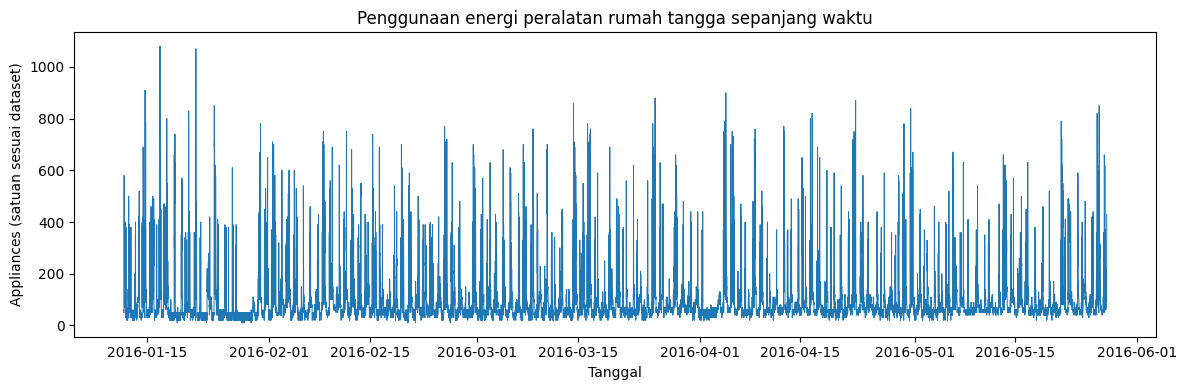

Statistik target:


,Appliances
count,19735.000000
mean,97.694958
std,102.524891
min,10.000000
25%,50.000000
50%,60.000000
75%,100.000000
max,1080.000000


In [4]:
plt.figure(figsize=(12, 4))
plt.plot(df["date"], df["Appliances"], linewidth=0.7)
plt.title("Penggunaan energi peralatan rumah tangga sepanjang waktu")
plt.xlabel("Tanggal")
plt.ylabel("Appliances (satuan sesuai dataset)")
plt.tight_layout()
plt.show()

print("Statistik target:")
display(df["Appliances"].describe().to_frame("Appliances"))

## 9. Rekayasa fitur dan pembagian data

Fitur tanggal diubah menjadi jam, hari dalam minggu, dan bulan. Dua kolom acak `rv1` dan `rv2` tidak digunakan sebagai prediktor. Data dibagi berdasarkan urutan waktu: 80% awal untuk pelatihan dan 20% akhir untuk pengujian.

In [5]:
data = df.copy()
data["hour"] = data["date"].dt.hour
data["day_of_week"] = data["date"].dt.dayofweek
data["month"] = data["date"].dt.month

target = "Appliances"
drop_cols = ["date", target, "rv1", "rv2"]
X = data.drop(columns=drop_cols, errors="ignore")
X = X.apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median()).fillna(0)
y = data[target].astype(float)

split_idx = int(len(data) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print("Rentang waktu latih:", data["date"].iloc[0], "s.d.", data["date"].iloc[split_idx-1])
print("Rentang waktu uji:", data["date"].iloc[split_idx], "s.d.", data["date"].iloc[-1])

Data latih: (15788, 28) | Data uji: (3947, 28)
Rentang waktu latih: 2016-01-11 17:00:00 s.d. 2016-04-30 08:10:00
Rentang waktu uji: 2016-04-30 08:20:00 s.d. 2016-05-27 18:00:00


## 10. Benchmark: satu core vs seluruh core yang tersedia

`n_jobs=1` menjalankan pekerjaan model menggunakan satu worker. `n_jobs=-1` meminta scikit-learn menggunakan seluruh core CPU yang tersedia untuk bagian Random Forest yang mendukung paralelisasi. Waktu dapat berbeda menurut jenis runtime, beban server, dan jumlah core yang diberikan Google Colab.

In [6]:
results = []
models = {}

for label, n_jobs in [("Serial (n_jobs=1)", 1), ("Paralel (n_jobs=-1)", -1)]:
    model = RandomForestRegressor(
        n_estimators=120,
        max_depth=None,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=n_jobs
    )

    start = time.perf_counter()
    model.fit(X_train, y_train)
    train_seconds = time.perf_counter() - start

    pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    results.append({
        "Konfigurasi": label,
        "Waktu latih (detik)": train_seconds,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    })
    models[label] = model

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Konfigurasi,Waktu latih (detik),MAE,RMSE,R²
0,Serial (n_jobs=1),44.7537,161.2309,201.5253,-3.9001
1,Paralel (n_jobs=-1),30.4140,161.2309,201.5253,-3.9001


## 11. Visualisasi perbandingan waktu dan kualitas prediksi

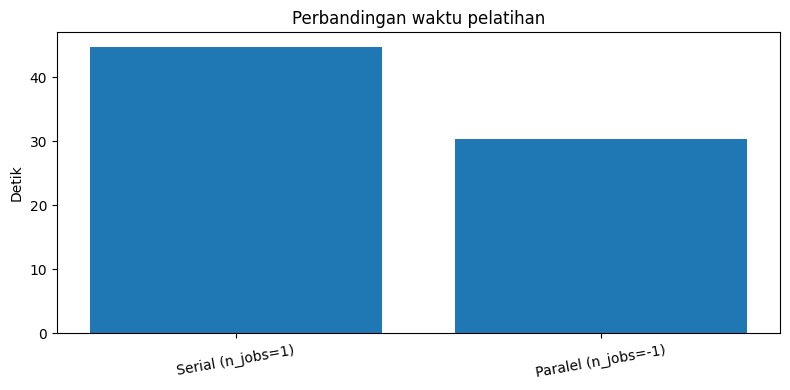

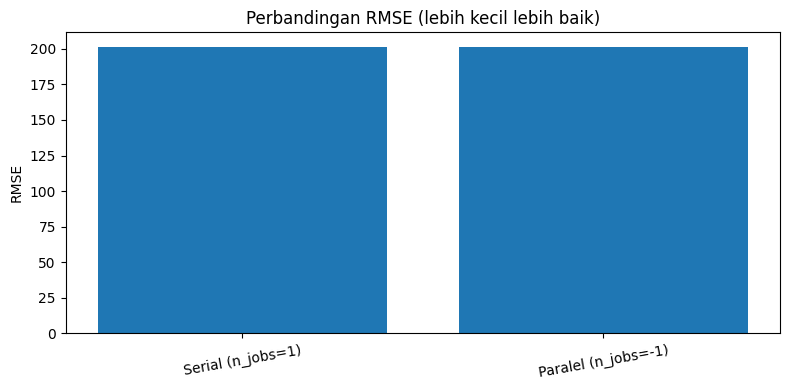

In [7]:
plt.figure(figsize=(8, 4))
plt.bar(results_df["Konfigurasi"], results_df["Waktu latih (detik)"])
plt.title("Perbandingan waktu pelatihan")
plt.ylabel("Detik")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.bar(results_df["Konfigurasi"], results_df["RMSE"])
plt.title("Perbandingan RMSE (lebih kecil lebih baik)")
plt.ylabel("RMSE")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

## 12. Prediksi aktual vs prediksi model paralel

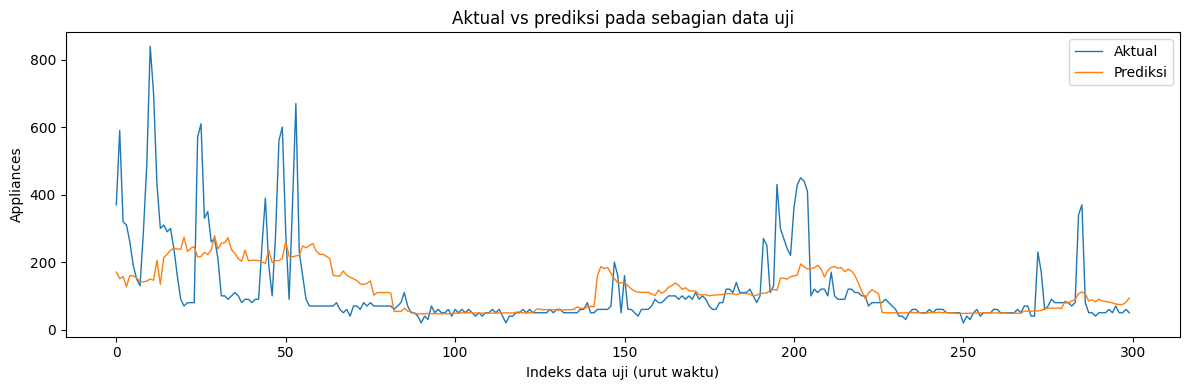

,Aktual,Prediksi
0,370.0,170.59
1,590.0,151.11
2,320.0,157.17
3,310.0,127.62
4,260.0,160.23
5,190.0,159.43
6,150.0,153.52
7,130.0,141.85
8,290.0,141.84
9,490.0,143.74


In [8]:
best_for_demo = models["Paralel (n_jobs=-1)"]
pred_test = best_for_demo.predict(X_test)

n_plot = min(300, len(y_test))
plt.figure(figsize=(12, 4))
plt.plot(np.arange(n_plot), y_test.iloc[:n_plot].to_numpy(), label="Aktual", linewidth=1)
plt.plot(np.arange(n_plot), pred_test[:n_plot], label="Prediksi", linewidth=1)
plt.title("Aktual vs prediksi pada sebagian data uji")
plt.xlabel("Indeks data uji (urut waktu)")
plt.ylabel("Appliances")
plt.legend()
plt.tight_layout()
plt.show()

comparison = pd.DataFrame({
    "Aktual": y_test.iloc[:15].to_numpy(),
    "Prediksi": pred_test[:15]
})
display(comparison.round(2))



## 13. Kesimpulan
Studi kasus ini menunjukkan alur penggunaan data science untuk memprediksi konsumsi energi dan memperkenalkan benchmarking komputasi paralel. Nilai MAE, RMSE, R², dan waktu pelatihan yang dihasilkan setelah eksekusi menjadi dasar untuk menilai kualitas model dan efisiensi komputasi. Relevansinya dengan materi webinar terletak pada pemilihan masalah nyata, pemanfaatan infrastruktur yang tersedia, pengukuran kinerja, dan pemahaman batasan sumber daya.
